In [1]:
# Cell 1: Imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from collections import defaultdict, Counter
import os
import numpy as np
import math

hf_token = os.environ.get("HF_TOKEN")

# Set plot style
plt.style.use('ggplot')
sns.set_palette("viridis")

# Cell 2: Load Dataset
print("Downloading dataset from HuggingFace...")

dataset = load_dataset("Bitext/Bitext-customer-support-llm-chatbot-training-dataset", token=hf_token)
print("Download complete")

Download complete


In [2]:
df = dataset['train'].to_pandas()
df.shape

(26872, 5)

In [3]:
df.head()

,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


In [4]:
df['word_count'] = df['instruction'].apply(lambda x : len(x.split()))
df.head()

,flags,instruction,category,intent,response,word_count
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...,6
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...,9
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...,7
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...,7
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...,9


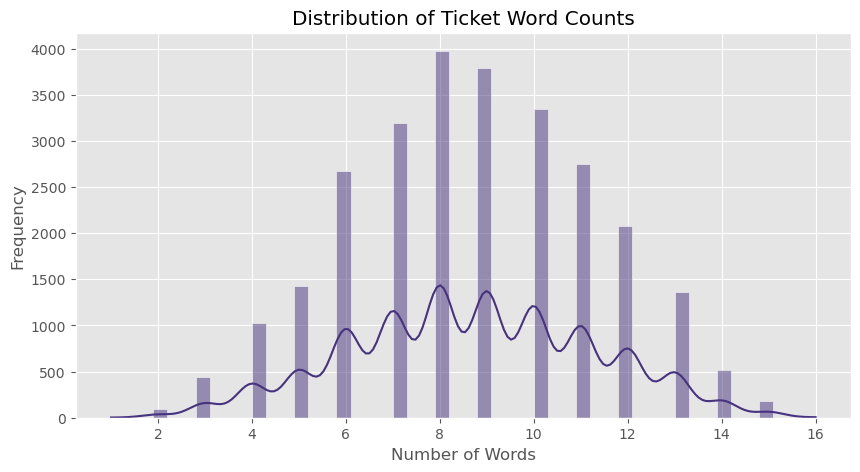

Average words per ticket: 8.69
Max words in a ticket: 16


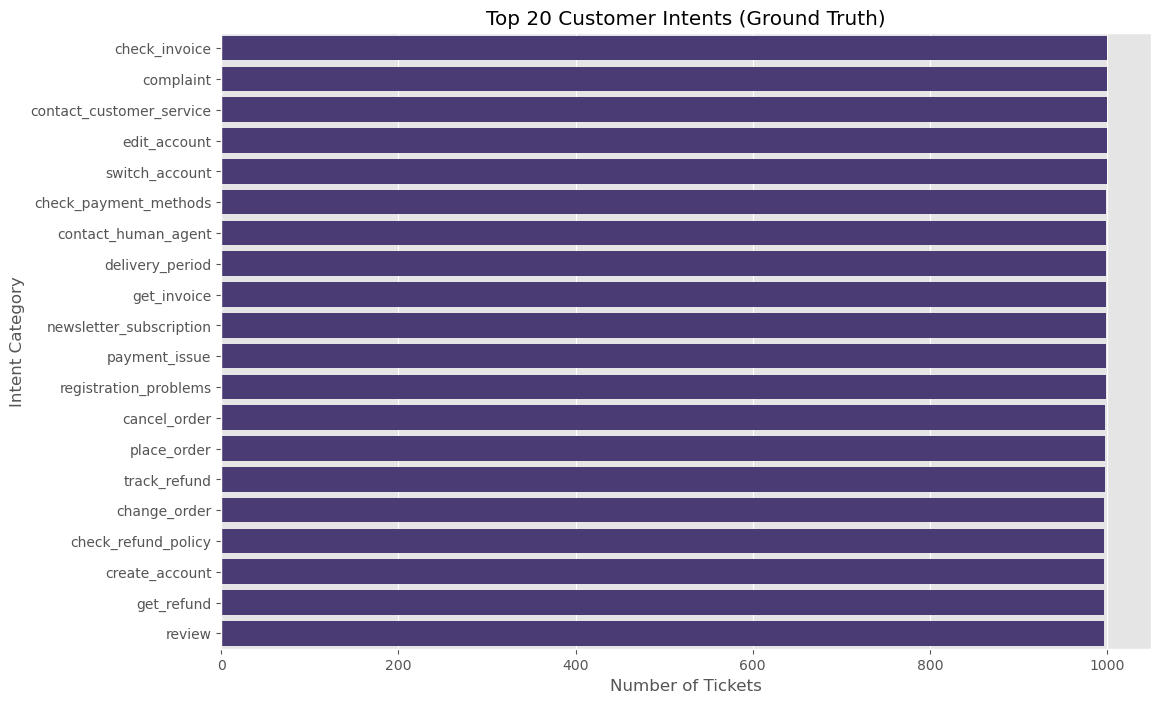

In [5]:
plt.figure(figsize=(10, 5))
sns.histplot(df['word_count'], bins=50, kde=True)
plt.title('Distribution of Ticket Word Counts')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.show()

print(f"Average words per ticket: {df['word_count'].mean():.2f}")
print(f"Max words in a ticket: {df['word_count'].max()}")

plt.figure(figsize=(12, 8))
intent_counts = df['intent'].value_counts().head(20) # Top 20 intents
sns.barplot(x=intent_counts.values, y=intent_counts.index)
plt.title('Top 20 Customer Intents (Ground Truth)')
plt.xlabel('Number of Tickets')
plt.ylabel('Intent Category')
plt.show()